
<table style="background-color: transparent;">
    <tr style="background-color: transparent; text-align:center;">
        <td width="100%" align="center"><font size="7" color="#6366F1">Computación Cuántica</font></td>
    </tr>
    <tr style="background-color: transparent; text-align:center;">
        <td width="100%"><font size="4" color="black">Temas Selectos de Ingeniería en Computación III</font></td>
    </tr>
    <tr style="background-color: transparent; text-align:center;">
        <td width="100%"><font size="4" color="black">2027-1</font></td>
    </tr>
    <tr style="background-color: transparent; text-align:center;">
        <td width="100%">
            <font size="6" color="#6366F1">
                Laboratorio 7:<br>
                Aprendizaje Automático Cuántico y Algoritmos Variacionales de Optimización
            </font>
        </td>
    </tr>
</table>



$$
\begin{gathered}
\phantom{\Large X}\\[5pt]
\huge \text{Introducción a la Optimización Cuántica mediante QAOA}
\end{gathered}
$$



$$
\begin{gathered}
\phantom{\Large X}
\huge \text{y el Problema MaxCut}
\end{gathered}
$$


# **Contenido**

1. [**Fundamentos del problema MaxCut**](#seccion-1)
2. [**Formulación de MaxCut mediante QUBO**](#seccion-2)
3. [**Transformación de QUBO a Hamiltonianos de Ising**](#seccion-3)
4. [**Algoritmo de Optimización Cuántica Aproximada (QAOA)**](#seccion-4)


<a name="seccion-1"></a>

# **1. Fundamentos del problema MaxCut**

La **optimización combinatoria** busca la mejor solución entre distintas configuraciones posibles, cuya exploración exhaustiva puede volverse computacionalmente costosa. El **Quantum Approximate Optimization Algorithm (QAOA)** combina circuitos cuánticos parametrizados y optimización clásica para buscar soluciones a estos problemas.

En este laboratorio utilizaremos **MaxCut** para estudiar el proceso:

$$
\boxed{
\text{Problema}
\longrightarrow
\text{QUBO}
\longrightarrow
\text{Ising}
\longrightarrow
\text{QAOA}
\longrightarrow
\text{Solución}
}
$$

El objetivo es **formular un problema clásico para su implementación cuántica**, ejecutar QAOA y comparar sus resultados con una solución clásica.


## 1.1. Introducción al problema MaxCut

El problema **MaxCut (*Maximum Cut*)** consiste en dividir los nodos de un grafo en dos grupos, de manera que se **maximice el número de aristas que conectan nodos de grupos diferentes**.

Un grafo no dirigido se representa mediante:

$$
G=(V,E)
$$

donde $V$ es el conjunto de **vértices o nodos** y $E$ el de **aristas**. Una arista está **cortada** si sus extremos pertenecen a grupos distintos; en caso contrario, no está cortada.

Por ejemplo, si los nodos $i$ y $j$ están conectados:

- Si ambos pertenecen al mismo grupo, su arista **no está cortada**.
- Si pertenecen a grupos diferentes, su arista **está cortada**.

El objetivo es encontrar la partición que produzca el **máximo número de cortes**.

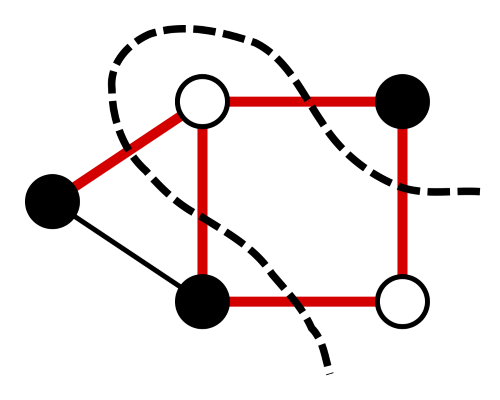


## 1.2. Formulación matemática de MaxCut

Para representar los dos grupos, asignamos una variable binaria a cada nodo:

$$
x_i=
\begin{cases}
0, & \text{si el nodo } i \text{ pertenece al grupo A},\\
1, & \text{si el nodo } i \text{ pertenece al grupo B}.
\end{cases}
$$

Una configuración del grafo queda descrita por el vector:

$$
\mathbf{x}=(x_0,x_1,\ldots,x_{n-1}), \qquad x_i\in\{0,1\}.
$$

Para determinar si una arista $(i,j)$ está cortada, definimos:

$$
d_{ij}=(x_i-x_j)^2
$$

Como las variables son binarias, $d_{ij}=1$ cuando los nodos pertenecen a grupos distintos y $d_{ij}=0$ cuando pertenecen al mismo grupo.

| $x_i$ | $x_j$ | $d_{ij}$ | ¿Hay corte? |
|:---:|:---:|:---:|:---:|
| 0 | 0 | 0 | No |
| 0 | 1 | 1 | Sí |
| 1 | 0 | 1 | Sí |
| 1 | 1 | 0 | No |

Sumando las contribuciones de todas las aristas obtenemos la **función objetivo de MaxCut**:

$$
\boxed{
C(\mathbf{x})=\sum_{(i,j)\in E}(x_i-x_j)^2
}
$$

Nuestro propósito es encontrar la configuración que **maximice el número de aristas cortadas**:

$$
\boxed{
\max_{\mathbf{x}\in\{0,1\}^{n}} C(\mathbf{x})
}
$$

En la **Sección 2** desarrollaremos algebraicamente esta función para obtener su formulación QUBO.



## 1.3. Ejemplo de MaxCut en un grafo

Trabajaremos con un grafo no dirigido formado por **4 nodos y 5 aristas**:

$$
V=\{0,1,2,3\}
$$

$$
E=\{(0,1),(0,2),(1,2),(1,3),(2,3)\}
$$

Construiremos el grafo utilizando **NetworkX** para visualizar sus conexiones y posteriormente evaluar distintas particiones.


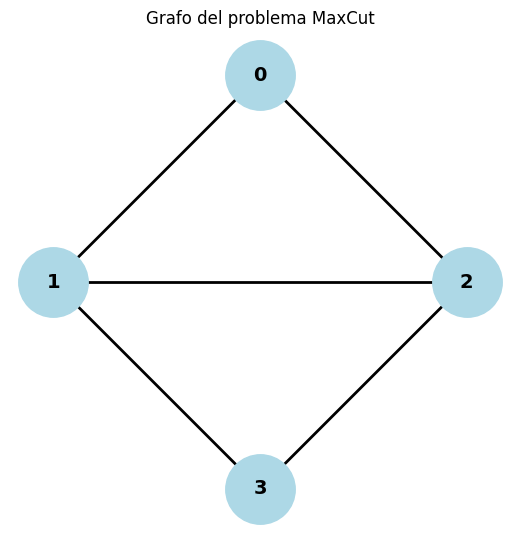

In [1]:
import networkx as nx
import matplotlib.pyplot as plt

# Definir los nodos y las aristas
n_nodes = 4
edges = [(0, 1), (0, 2), (1, 2), (1, 3), (2, 3)]

# Construir el grafo no dirigido
G = nx.Graph()
G.add_nodes_from(range(n_nodes))
G.add_edges_from(edges)

# Fijar las posiciones de los nodos
pos = {0: (0, 1), 1: (-1, 0), 2: (1, 0), 3: (0, -1)}

# Visualizar el grafo
plt.figure(figsize=(5, 5))
nx.draw(G, pos, with_labels=True, node_color="lightblue", node_size=2500, font_size=14, font_weight="bold", width=2)
plt.title("Grafo del problema MaxCut")
plt.show()


### Ejemplo de una partición

Consideremos la siguiente división del grafo:

- **Grupo A:** $\{0,3\}$
- **Grupo B:** $\{1,2\}$

Su representación binaria es:

$$
\boxed{\mathbf{x}=(0,1,1,0)}
$$

Evaluemos las cinco aristas:

| Arista | Grupos conectados | ¿Hay corte? |
|:---:|:---:|:---:|
| $(0,1)$ | A–B | Sí |
| $(0,2)$ | A–B | Sí |
| $(1,2)$ | B–B | No |
| $(1,3)$ | B–A | Sí |
| $(2,3)$ | B–A | Sí |

Por tanto, la función objetivo toma el valor:

$$
C(0,1,1,0)=1+1+0+1+1
$$

$$
\boxed{C(0,1,1,0)=4}
$$

Esta configuración produce **4 aristas cortadas de un total de 5**.

Visualicemos la partición utilizando colores diferentes para cada grupo y resaltando las aristas cortadas.


Configuración: [0, 1, 1, 0] | Aristas cortadas: [(0, 1), (0, 2), (1, 3), (2, 3)] | Número de cortes: 4


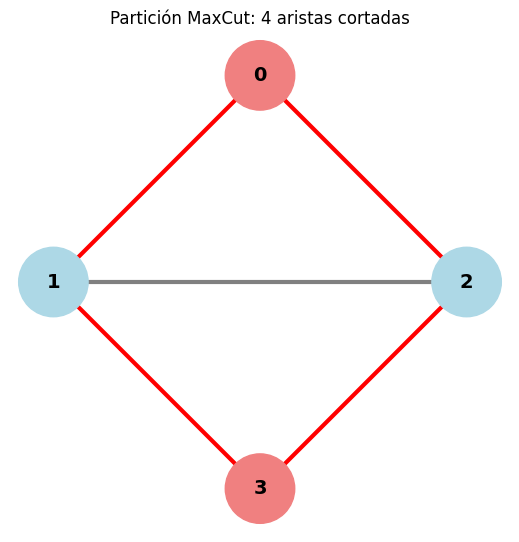

In [2]:
# Definir la partición e identificar las aristas cortadas
solution = [0, 1, 1, 0]
cut_edges = [(i, j) for i, j in edges if solution[i] != solution[j]]

print(f"Configuración: {solution} | Aristas cortadas: {cut_edges} | Número de cortes: {len(cut_edges)}")

# Colorear nodos por grupo y resaltar aristas cortadas
node_colors = ["lightcoral" if solution[i] == 0 else "lightblue" for i in G.nodes()]
edge_colors = ["red" if solution[i] != solution[j] else "gray" for i, j in G.edges()]

# Visualizar la partición
plt.figure(figsize=(5, 5))
nx.draw(G, pos, with_labels=True, node_color=node_colors, edge_color=edge_colors, node_size=2500, font_size=14, font_weight="bold", width=3)
plt.title("Partición MaxCut: 4 aristas cortadas")
plt.show()

### Búsqueda de la solución óptima clásica

Hemos encontrado una configuración con **4 cortes**, pero necesitamos comprobar si es la mejor solución posible.

Como cada nodo puede pertenecer a dos grupos y tenemos cuatro nodos, existen:

$$
2^4=16
$$

configuraciones binarias posibles.

Evaluaremos todas mediante **búsqueda exhaustiva (fuerza bruta)**, utilizando la función objetivo:

$$
C(\mathbf{x})=\sum_{(i,j)\in E}(x_i-x_j)^2
$$

El máximo obtenido servirá como referencia clásica para comparar posteriormente los resultados de QAOA.


In [3]:
from itertools import product

# Inicializar el mejor resultado
best_value = -1
best_solutions = []

# Evaluar las 16 configuraciones binarias
for x in product([0, 1], repeat=n_nodes):

    # Calcular la función objetivo de MaxCut
    cuts = sum((x[i] - x[j])**2 for i, j in edges)
    print(f"x = {x} | Cortes = {cuts}")

    # Actualizar el máximo y guardar sus configuraciones
    if cuts > best_value:
        best_value = cuts
        best_solutions = [x]
    elif cuts == best_value:
        best_solutions.append(x)

print("\nNúmero máximo de cortes:", best_value)
print("Configuraciones óptimas:", best_solutions)

x = (0, 0, 0, 0) | Cortes = 0
x = (0, 0, 0, 1) | Cortes = 2
x = (0, 0, 1, 0) | Cortes = 3
x = (0, 0, 1, 1) | Cortes = 3
x = (0, 1, 0, 0) | Cortes = 3
x = (0, 1, 0, 1) | Cortes = 3
x = (0, 1, 1, 0) | Cortes = 4
x = (0, 1, 1, 1) | Cortes = 2
x = (1, 0, 0, 0) | Cortes = 2
x = (1, 0, 0, 1) | Cortes = 4
x = (1, 0, 1, 0) | Cortes = 3
x = (1, 0, 1, 1) | Cortes = 3
x = (1, 1, 0, 0) | Cortes = 3
x = (1, 1, 0, 1) | Cortes = 3
x = (1, 1, 1, 0) | Cortes = 2
x = (1, 1, 1, 1) | Cortes = 0

Número máximo de cortes: 4
Configuraciones óptimas: [(0, 1, 1, 0), (1, 0, 0, 1)]



La búsqueda exhaustiva confirma que el **máximo es de 4 cortes**, alcanzado por dos configuraciones equivalentes que intercambian los grupos A y B:

$$
\boxed{
C_{\max}=4,\qquad
\mathbf{x}^{(1)}=(0,1,1,0),\quad
\mathbf{x}^{(2)}=(1,0,0,1)
}
$$

**¿Por qué no pueden cortarse las cinco aristas?**

Los nodos $0,1,2$ forman un triángulo con aristas $(0,1),(0,2),(1,2)$. Al dividir sus vértices en solo dos grupos, **al menos dos nodos deben pertenecer al mismo grupo**, dejando una arista sin cortar. Por tanto:

$$
\boxed{C_{\max}\leq 5-1=4}
$$

Como encontramos configuraciones con cuatro cortes, **queda demostrado que este es el máximo posible**. Así establecemos la solución clásica de MaxCut.



<a name="seccion-2"></a>

# **2. Formulación de MaxCut mediante QUBO**

En la sección anterior definimos MaxCut mediante la función:

$$
C(\mathbf{x})=\sum_{(i,j)\in E}(x_i-x_j)^2
$$

Ahora transformaremos esta expresión en un problema **QUBO (*Quadratic Unconstrained Binary Optimization*)**, que consiste en optimizar una función cuadrática de variables binarias sin restricciones adicionales.

Su representación general es:

$$
\boxed{
f(\mathbf{x})=\mathbf{x}^{T}Q\mathbf{x},
\qquad x_i\in\{0,1\}
}
$$

donde $Q$ es una matriz de coeficientes que representa las contribuciones individuales y las interacciones entre variables.



## 2.1. Construcción de la función QUBO

En la Sección 1 definimos el número de aristas cortadas mediante:

$$
C(\mathbf{x})=\sum_{(i,j)\in E}(x_i-x_j)^2
$$

Para expresar esta función en términos cuadráticos, desarrollamos la contribución de cada arista:

$$
(x_i-x_j)^2=x_i^2+x_j^2-2x_ix_j
$$

Como las variables son **binarias**, $x_i\in\{0,1\}$, se cumple $x_i^2=x_i$. Por tanto:

$$
\boxed{(x_i-x_j)^2=x_i+x_j-2x_ix_j}
$$

Sustituyendo en la función objetivo:

$$
\boxed{
C(\mathbf{x})=\sum_{(i,j)\in E}(x_i+x_j-2x_ix_j)
}
$$

Para nuestro grafo, con $E=\{(0,1),(0,2),(1,2),(1,3),(2,3)\}$, cada arista aporta un término:

$$
\begin{aligned}
C(\mathbf{x})={}&(x_0+x_1-2x_0x_1)\\
&+(x_0+x_2-2x_0x_2)\\
&+(x_1+x_2-2x_1x_2)\\
&+(x_1+x_3-2x_1x_3)\\
&+(x_2+x_3-2x_2x_3)
\end{aligned}
$$

Agrupando términos, $x_0$ y $x_3$ aparecen dos veces, mientras que $x_1$ y $x_2$ aparecen tres:

$$
\boxed{
\begin{aligned}
C(\mathbf{x})={}&2x_0+3x_1+3x_2+2x_3\\
&-2(x_0x_1+x_0x_2+x_1x_2+x_1x_3+x_2x_3)
\end{aligned}
}
$$


Hemos obtenido una función con estructura **QUBO (*Quadratic Unconstrained Binary Optimization*)**, formada por términos lineales y cuadráticos de variables binarias sin restricciones adicionales.

Esta formulación permite organizar sus coeficientes en una **matriz $Q$** y representar MaxCut en un formato estándar de optimización. Posteriormente, transformaremos sus variables binarias en espines de Ising para construir el Hamiltoniano cuántico.



## 2.2. Representación matricial del QUBO

Una función QUBO puede representarse mediante:

$$
\boxed{C(\mathbf{x})=\mathbf{x}^{T}Q\mathbf{x}}
$$

Para nuestro problema:

$$
\mathbf{x}=
\begin{pmatrix}
x_0\\
x_1\\
x_2\\
x_3
\end{pmatrix}
$$

La matriz $Q$ se construye directamente con los coeficientes obtenidos en la Sección 2.1.

**1. Coeficientes lineales: diagonal de $Q$.**

Los términos $2x_0+3x_1+3x_2+2x_3$ se colocan en la diagonal porque, al ser variables binarias, $x_i^2=x_i$:

$$
Q_{00}=2,\quad Q_{11}=3,\quad Q_{22}=3,\quad Q_{33}=2
$$

**2. Interacciones: elementos fuera de la diagonal.**

Los cinco términos cuadráticos determinan las siguientes posiciones:

$$
\begin{aligned}
-2x_0x_1 &\longrightarrow Q_{01}=-2\\
-2x_0x_2 &\longrightarrow Q_{02}=-2\\
-2x_1x_2 &\longrightarrow Q_{12}=-2\\
-2x_1x_3 &\longrightarrow Q_{13}=-2\\
-2x_2x_3 &\longrightarrow Q_{23}=-2
\end{aligned}
$$

Colocamos cada interacción una sola vez, utilizando una **matriz triangular superior**. Las posiciones restantes son cero.

Así obtenemos:

$$
\boxed{
Q=
\begin{pmatrix}
2 & -2 & -2 & 0\\
0 & 3 & -2 & -2\\
0 & 0 & 3 & -2\\
0 & 0 & 0 & 2
\end{pmatrix}
}
$$

**La matriz $Q$ organiza los coeficientes de nuestra función objetivo en una representación matricial.**

Comprobemos que esta matriz reproduce el resultado obtenido en la Sección 1 para la configuración $\mathbf{x}=(0,1,1,0)$, que produce cuatro aristas cortadas:

$$
\boxed{\mathbf{x}^{T}Q\mathbf{x}=4}
$$


In [4]:
import numpy as np

# Construir la matriz QUBO
Q = np.array([[2, -2, -2, 0],
              [0,  3, -2, -2],
              [0,  0,  3, -2],
              [0,  0,  0,  2]])

# Evaluar la configuración óptima de la Sección 1
x = np.array([0, 1, 1, 0])
valor_qubo = x @ Q @ x

print("Configuración:", x)
print("Valor QUBO:", valor_qubo)

Configuración: [0 1 1 0]
Valor QUBO: 4



<a name="seccion-3"></a>

# **3. Transformación de QUBO a Hamiltonianos de Ising**

En la Sección 2 expresamos MaxCut mediante la **formulación QUBO**:

$$
C(\mathbf{x})=\mathbf{x}^{T}Q\mathbf{x}
$$

Para implementar QAOA necesitamos construir un **Hamiltoniano** cuyas energías representen las soluciones del problema. Utilizaremos el **modelo de Ising**, basado en variables de espín con valores $+1$ y $-1$, que podemos relacionar con los estados de los qubits.

Aunque QUBO organiza la función objetivo en una matriz $Q$, para MaxCut podemos obtener el Hamiltoniano directamente mediante un **cambio de variables**, sin desarrollar explícitamente dicha matriz.



## 3.1. De variables binarias a espines de Ising

En MaxCut, cada nodo está representado por una variable binaria:

$$
x_i\in\{0,1\}
$$

En el modelo de Ising utilizamos variables llamadas **espines**, que pueden tomar dos valores:

$$
z_i\in\{-1,+1\}
$$

Podemos transformar una variable binaria en un espín mediante:

$$
\boxed{z_i=1-2x_i}
$$

De manera equivalente:

$$
\boxed{x_i=\frac{1-z_i}{2}}
$$

Esta transformación establece la siguiente correspondencia:

| Variable binaria | Espín de Ising | Grupo |
|:---:|:---:|:---:|
| $x_i=0$ | $z_i=+1$ | A |
| $x_i=1$ | $z_i=-1$ | B |

Ahora sustituimos esta relación en la contribución de una arista:

$$
(x_i-x_j)^2
=
\left(\frac{1-z_i}{2}-\frac{1-z_j}{2}\right)^2=\frac{(z_i-z_j)^2}{4}=\frac{1-z_iz_j}{2}
$$

**Interpretación física:**

- Si los espines tienen el mismo signo, $z_iz_j=+1$, la arista aporta $0$ cortes.
- Si tienen signos opuestos, $z_iz_j=-1$, la arista aporta $1$ corte.

Por tanto, la función MaxCut queda expresada en términos de espines:

$$
\boxed{
C(\mathbf{z})=\frac{1}{2}\sum_{(i,j)\in E}(1-z_iz_j)
}
$$

Hemos pasado de variables binarias a variables de Ising sin modificar el valor de la función objetivo.



## 3.2. Construcción del Hamiltoniano de Ising

<h3 align="center"><u>Del espín clásico al operador de Pauli Z</u></h3>

Representamos los espines $z_i\in\{-1,+1\}$ mediante el **operador de Pauli $Z$**:

$$
\boxed{
Z=\begin{pmatrix}1&0\\0&-1\end{pmatrix},
\qquad
Z|0\rangle=(+1)|0\rangle,\quad
Z|1\rangle=(-1)|1\rangle
}
$$

Los estados $|0\rangle$ y $|1\rangle$ son **autoestados de $Z$**, cuyos autovalores coinciden con los espines clásicos. Por tanto:

$$
\boxed{z_i\longrightarrow Z_i}
$$

donde $Z_i$ actúa sobre el qubit $i$ y como identidad sobre los demás.


<h3 align="center"><u>Interacciones entre dos qubits</u></h3>

La interacción clásica $z_iz_j$ se representa mediante $Z_iZ_j$, cuya acción sobre la base computacional es:

$$
\boxed{
\begin{aligned}
Z_iZ_j|00\rangle&=(+1)|00\rangle\\
Z_iZ_j|11\rangle&=(+1)|11\rangle\\
Z_iZ_j|01\rangle&=(-1)|01\rangle\\
Z_iZ_j|10\rangle&=(-1)|10\rangle
\end{aligned}
}
$$

Los **autovalores $+1$** corresponden a nodos del mismo grupo (**sin corte**), mientras que los **autovalores $-1$** corresponden a grupos distintos (**con corte**).

Así, $\frac12(I-Z_iZ_j)$ tiene autovalor **1 si la arista está cortada y 0 en caso contrario**. Sumando las contribuciones:

$$
\boxed{
\hat C=\frac12\sum_{(i,j)\in E}(I-Z_iZ_j)
}
$$

<h3 align="center"><u>Hamiltoniano de costo</u></h3>

Como MaxCut busca **maximizar los cortes**, cambiamos el signo para formular una **minimización de energía**:

$$
\boxed{
H_C=-\hat C=\frac12\sum_{(i,j)\in E}(Z_iZ_j-I)
}
$$

Cada arista cortada aporta energía $-1$, mientras que una no cortada aporta $0$. Por tanto, **minimizar $H_C$ equivale a maximizar los cortes**.

Para nuestro grafo de cinco aristas:

$$
\boxed{
H_C=
\underbrace{\frac12(Z_0Z_1+Z_0Z_2+Z_1Z_2+Z_1Z_3+Z_2Z_3)}_{H_{\mathrm{Ising}}}
-\frac52 I
}
$$

El término $-\frac52 I$, denominado **offset**, proviene de las cinco contribuciones constantes $-\frac12 I$. Desplaza todas las energías por igual, **sin modificar qué configuración las minimiza**.

Podemos optimizar $H_{\mathrm{Ising}}$ y recuperar la energía completa mediante:

$$
\boxed{
E_C(\mathbf{x})=E_{\mathrm{Ising}}(\mathbf{x})-\frac52=-C(\mathbf{x})
}
$$



## 3.3. Comprobación de las energías de Ising

Comprobemos esta transformación utilizando una de las configuraciones óptimas de MaxCut:

$$
\mathbf{x}=(0,1,1,0)
$$

Aplicando $z_i=1-2x_i$, obtenemos:

$$
\mathbf{z}=(+1,-1,-1,+1)
$$

Para esta configuración, la energía del Hamiltoniano de Ising es:

$$
\begin{aligned}
E_{\mathrm{Ising}}
=\frac{1}{2}(z_0z_1+z_0z_2+z_1z_2+z_1z_3+z_2z_3)
=\frac{1}{2}(-1-1+1-1-1)
=-\frac{3}{2}
\end{aligned}
$$

Al incorporar el offset:

$$
E_C=-\frac{3}{2}-\frac{5}{2}=-4
$$

Obtenemos así:

$$
\boxed{E_C=-4=-C(\mathbf{x})}
$$


Hemos transformado la función QUBO de MaxCut en un **Hamiltoniano de Ising**:

$$
\boxed{
H_C=\frac{1}{2}\sum_{(i,j)\in E}(Z_iZ_j-I)
}
$$

La correspondencia entre ambas formulaciones es:

$$
\boxed{
x_i\in\{0,1\}
\quad\longrightarrow\quad
z_i=1-2x_i
\quad\longrightarrow\quad
Z_i
}
$$

Comprobamos que **las configuraciones que maximizan el número de cortes también minimizan la energía**:

$$
\boxed{C_{\max}=4\quad\Longleftrightarrow\quad E_{\min}=-4}
$$

En la **Sección 4** utilizaremos el Hamiltoniano de Ising para implementar QAOA mediante un circuito cuántico parametrizado y un optimizador clásico.


<a name="seccion-4"></a>

# **4. Algoritmo de Optimización Cuántica Aproximada (QAOA)**

In [5]:
%pip install -q pennylane


<a name="seccion-4"></a>

# **4. Algoritmo de Optimización Cuántica Aproximada (QAOA)**

El **Quantum Approximate Optimization Algorithm (QAOA)** es un algoritmo **híbrido cuántico-clásico** que utiliza un circuito parametrizado para buscar configuraciones que minimicen el Hamiltoniano de costo $H_C$, obtenido en la Sección 3.

El circuito parte de una **superposición uniforme** y aplica alternadamente dos operadores:

1. El **operador de costo** $U_C(\gamma)$.
2. El **operador mezclador** $U_M(\beta)$.

Para una profundidad de $p$ capas, el estado resultante es:

$$
\boxed{
|\psi(\boldsymbol{\gamma},\boldsymbol{\beta})\rangle
=
U_M(\beta_p)U_C(\gamma_p)
\cdots
U_M(\beta_1)U_C(\gamma_1)
|+\rangle^{\otimes n}
}
$$

donde $n$ es el número de qubits y $\boldsymbol{\gamma},\boldsymbol{\beta}$ son los **parámetros variacionales** que ajusta un optimizador clásico.

En nuestro caso utilizaremos **$n=4$ qubits**, uno por cada vértice del grafo de la Sección 1, y **$p=3$ capas**.

Los cuatro qubits permiten representar simultáneamente las **$2^4=16$ configuraciones de MaxCut** mediante una superposición:

$$
\boxed{
|\psi_0\rangle
=
|+\rangle^{\otimes4}
=
\frac14\sum_{\mathbf{x}\in\{0,1\}^4}|\mathbf{x}\rangle
}
$$

Cada estado $|\mathbf{x}\rangle$ representa una partición del grafo. Inicialmente, las 16 configuraciones tienen la **misma probabilidad $P(\mathbf{x})=1/16$**.

El objetivo de QAOA es **modificar esta distribución mediante las fases introducidas por el operador de costo y la interferencia producida por el mezclador**, favoreciendo las configuraciones de menor energía.


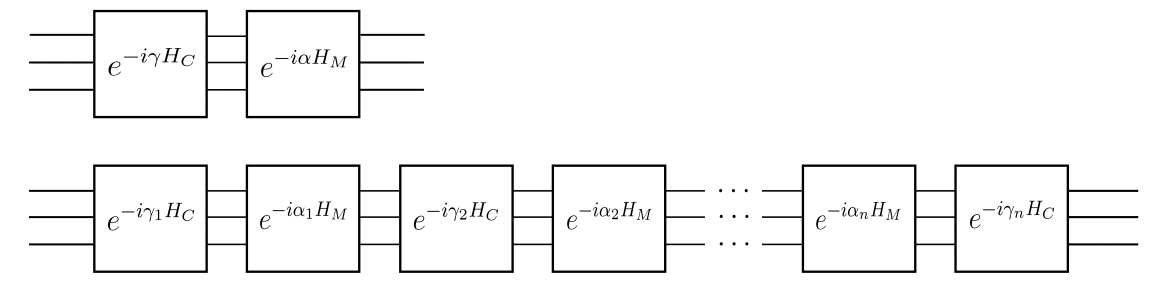


## 4.1. Operador de costo

El **operador de costo** utiliza el Hamiltoniano $H_C$, obtenido en la Sección 3, para introducir **fases dependientes de la energía** de cada configuración:

$$
\boxed{U_C(\gamma)=e^{-i\gamma H_C}}
$$

donde $\gamma$ es el **parámetro variacional** que controla la evolución.

<h3 align="center"><u>Relación entre energía y fase</u></h3>

Cada configuración $|\mathbf{x}\rangle$ es un autoestado del Hamiltoniano de Ising, con energía $E(\mathbf{x})$:

$$
\boxed{
H_C|\mathbf{x}\rangle=E(\mathbf{x})|\mathbf{x}\rangle
}
$$

Al aplicar el operador de costo:

$$
\boxed{
\begin{aligned}
U_C(\gamma)|\mathbf{x}\rangle
&=e^{-i\gamma H_C}|\mathbf{x}\rangle\\
&=e^{-i\gamma E(\mathbf{x})}|\mathbf{x}\rangle
\end{aligned}
}
$$

**¿Qué ocurre con las 16 configuraciones?**

Cada amplitud adquiere una fase según su energía:

$$
\boxed{
|\psi_1\rangle
=
U_C(\gamma)|\psi_0\rangle
=
\frac14\sum_{\mathbf{x}\in\{0,1\}^4}
e^{-i\gamma E(\mathbf{x})}|\mathbf{x}\rangle
}
$$

Sin embargo, la probabilidad de cada configuración permanece igual:

$$
P(\mathbf{x})
=
\left|\frac14e^{-i\gamma E(\mathbf{x})}\right|^2
=
\boxed{\frac1{16}}
$$

Por tanto, **el operador de costo distingue las configuraciones mediante sus fases, pero todavía no favorece ninguna al medir**. Para modificar sus probabilidades necesitaremos el mezclador de la Sección 4.2.

<h3 align="center"><u>Implementación mediante compuertas</u></h3>

Recuperamos el Hamiltoniano de la Sección 3:

$$
\begin{aligned}
H_C
&=\frac12\sum_{(i,j)\in E}(Z_iZ_j-I)\\
&=\frac12\sum_{(i,j)\in E}Z_iZ_j-\frac{|E|}{2}I
\end{aligned}
$$

Aquí, $|E|$ es el **número de aristas**, de modo que $\sum_{(i,j)\in E}I=|E|I$.

Sustituyendo:

$$
U_C(\gamma)
=
\exp\left[
-\frac{i\gamma}{2}\sum_{(i,j)\in E}Z_iZ_j
+\frac{i\gamma|E|}{2}I
\right]
$$

Como **todos los términos conmutan**, podemos factorizar la exponencial mediante $e^{A+B}=e^Ae^B$, válido cuando $AB=BA$:

$$
\boxed{
U_C(\gamma)=
\underbrace{e^{i\gamma|E|/2}}_{\text{Fase global}}
\underbrace{\prod_{(i,j)\in E}e^{-i\gamma Z_iZ_j/2}}_{\text{Interacciones ZZ}}
}
$$

La **fase global** no modifica las probabilidades ni las diferencias de fase entre configuraciones, por lo que podemos omitirla al construir el circuito. Necesitamos implementar **una interacción $ZZ$ por arista**:

$$
\boxed{U_{ZZ}(\gamma)=e^{-i\gamma Z_iZ_j/2}}
$$

El operador $Z_iZ_j$ tiene autovalor $+1$ cuando ambos bits son iguales y $-1$ cuando son diferentes:

$$
\boxed{
U_{ZZ}(\gamma)|x_ix_j\rangle=
\begin{cases}
e^{-i\gamma/2}|x_ix_j\rangle,&x_i=x_j\\
e^{+i\gamma/2}|x_ix_j\rangle,&x_i\ne x_j
\end{cases}
}
$$

Estas fases se implementan mediante la secuencia **CNOT–RZ–CNOT**.

La primera CNOT convierte el segundo bit en $x_i\oplus x_j$, donde $\oplus$ es la suma módulo 2. La rotación $R_Z(\gamma)$ introduce la fase correspondiente, y la segunda CNOT restaura los bits originales.

| Estado inicial | Primera CNOT | Fase de $R_Z$ | Estado final |
|:---:|:---:|:---:|:---:|
| $|00\rangle$ | $|00\rangle$ | $e^{-i\gamma/2}$ | $e^{-i\gamma/2}|00\rangle$ |
| $|01\rangle$ | $|01\rangle$ | $e^{+i\gamma/2}$ | $e^{+i\gamma/2}|01\rangle$ |
| $|10\rangle$ | $|11\rangle$ | $e^{+i\gamma/2}$ | $e^{+i\gamma/2}|10\rangle$ |
| $|11\rangle$ | $|10\rangle$ | $e^{-i\gamma/2}$ | $e^{-i\gamma/2}|11\rangle$ |

Como las fases coinciden exactamente, obtenemos:

$$
\boxed{
e^{-i\gamma Z_iZ_j/2}
=
\operatorname{CNOT}_{i,j}
R_Z^{(j)}(\gamma)
\operatorname{CNOT}_{i,j}
}
$$

Una capa de costo contiene **$2|E|$ CNOT y $|E|$ rotaciones $R_Z$**, antes de simplificar el circuito.

<h3 align="center"><u>Implementación en PennyLane</u></h3>

Construiremos el operador de costo aplicando la secuencia **CNOT–RZ–CNOT a cada arista** del grafo. Utilizaremos $\gamma=0.7$ solamente para visualizar el circuito.


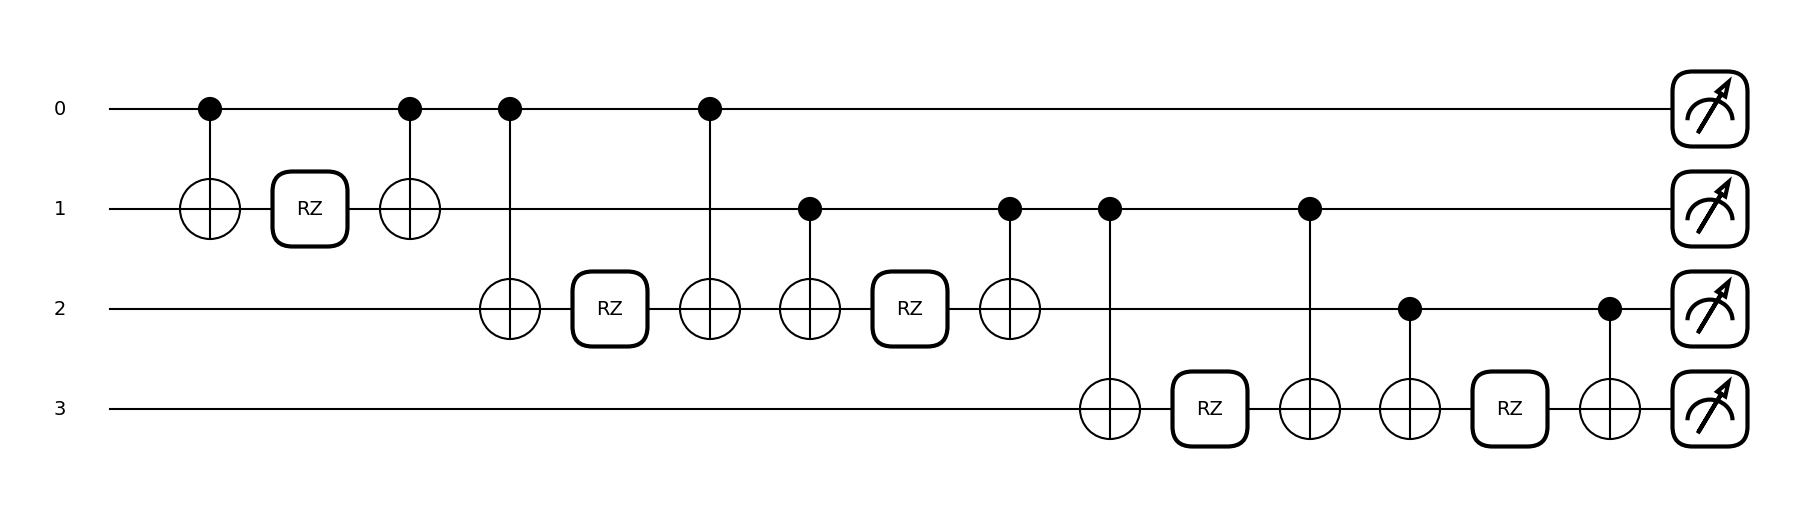

In [6]:
import pennylane as qml
import matplotlib.pyplot as plt

# Construir el operador de costo, omitiendo la fase global
def cost_layer(gamma):
    for i, j in edges:
        # Interacción ZZ: CNOT - RZ - CNOT
        qml.CNOT(wires=[i, j])
        qml.RZ(gamma, wires=j)
        qml.CNOT(wires=[i, j])

# Crear el simulador con un qubit por vértice
dev = qml.device("default.qubit", wires=n_nodes)

# Circuito auxiliar para visualizar las interacciones
@qml.qnode(dev)
def circuito_costo(gamma):
    cost_layer(gamma)
    return qml.state()

# Mostrar el circuito con un ángulo ilustrativo
fig, ax = qml.draw_mpl(circuito_costo)(0.7)
plt.show()


## 4.2. Operador mezclador

El **operador mezclador** permite que las amplitudes con diferentes fases, introducidas por el operador de costo, **interfieran y modifiquen las probabilidades de medición**.

Definimos el **Hamiltoniano mezclador** y su evolución unitaria:

$$
\boxed{
H_M=\sum_{i=0}^{n-1}X_i,
\qquad
U_M(\beta)=e^{-i\beta H_M}
}
$$

donde $X_i$ es el operador de Pauli $X$ que actúa sobre el qubit $i$, y $\beta$ es el **parámetro variacional**.

<h3 align="center"><u>Implementación mediante compuertas</u></h3>

Sustituimos el Hamiltoniano mezclador en su evolución unitaria:

$$
U_M(\beta)=
\exp\left(-i\beta\sum_{i=0}^{n-1}X_i\right)
$$

Como los operadores $X_i$ actúan sobre qubits diferentes, **conmutan entre sí**. Podemos factorizar la exponencial:

$$
U_M(\beta)=\prod_{i=0}^{n-1}e^{-i\beta X_i}
$$

La compuerta de rotación alrededor del eje $X$ se define como:

$$
\boxed{R_X(\theta)=e^{-i\theta X/2}}
$$

Para identificar cada factor del producto con una rotación $R_X$, igualamos los exponentes:

$$
-i\beta X=-i\frac{\theta}{2}X
\quad\Longrightarrow\quad
\boxed{\theta=2\beta}
$$

Sustituyendo, obtenemos:

$$
\boxed{
U_M(\beta)=\prod_{i=0}^{n-1}R_X^{(i)}(2\beta)
}
$$

Por tanto, **cada capa mezcladora aplica una rotación $R_X(2\beta)$ sobre cada qubit**.

<h3 align="center"><u>Interferencia entre amplitudes</u></h3>

Para observar su efecto, consideremos un **ejemplo ilustrativo de un qubit**. Sea $|\psi_C\rangle$ el estado después de introducir una diferencia de fase de $\pi/2$:

$$
|\psi_C\rangle=\frac{|0\rangle+i|1\rangle}{\sqrt2}
$$

Ambos estados tienen inicialmente **probabilidad del 50%**. Elegimos $\beta=\pi/4$, por lo que la compuerta aplicada es $R_X(2\beta)=R_X(\pi/2)$.

Esta rotación transforma los estados de la siguiente manera:

$$
\begin{aligned}
R_X(\pi/2)|0\rangle
&=\frac{|0\rangle-i|1\rangle}{\sqrt2}\\
R_X(\pi/2)|1\rangle
&=\frac{|1\rangle-i|0\rangle}{\sqrt2}
\end{aligned}
$$

Aplicándola a la superposición:

$$
\begin{aligned}
|\psi_M\rangle
&=R_X(\pi/2)|\psi_C\rangle\\
&=\frac12\left[(|0\rangle-i|1\rangle)
+i(|1\rangle-i|0\rangle)\right]\\
&=\boxed{|0\rangle}
\end{aligned}
$$

Aquí, $|\psi_M\rangle$ es el **estado después del mezclador**.

| Estado | Antes | Después |
|:---:|:---:|:---:|
| $|0\rangle$ | 50% | **100%** |
| $|1\rangle$ | 50% | **0%** |

La **interferencia constructiva** refuerza $|0\rangle$, mientras que la **destructiva** cancela $|1\rangle$. Este mecanismo permite redistribuir las probabilidades de las **16 configuraciones de MaxCut**.

<h3 align="center"><u>Implementación en PennyLane</u></h3>

Implementaremos una rotación $R_X(2\beta)$ por qubit, reutilizando `n_nodes` y `dev` de la Sección 4.1. El valor $\beta=0.4$ se utiliza únicamente para visualizar el circuito.


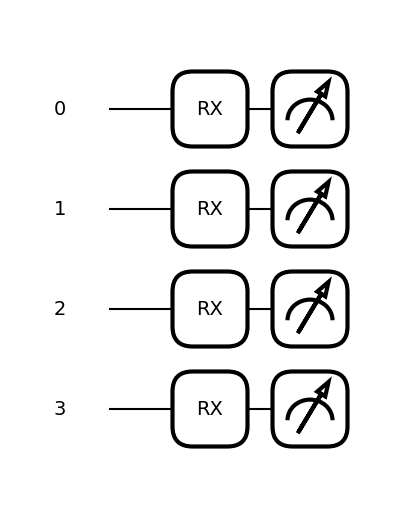

In [7]:
# Operador mezclador: una rotación RX por qubit
def mixer_layer(beta):
    for i in range(n_nodes):
        qml.RX(2 * beta, wires=i)

# Circuito auxiliar para visualizar el mezclador
@qml.qnode(dev)
def circuito_mezclador(beta):
    mixer_layer(beta)
    return qml.state()

# Visualizar el circuito con beta = 0.4
fig, ax = qml.draw_mpl(circuito_mezclador)(0.4)
plt.show()

## 4.3. Optimización variacional de QAOA

<h3 align="center"><u>Construcción del circuito QAOA</u></h3>

Combinamos los operadores de las secciones 4.1 y 4.2 en un circuito de **$p=3$ capas**:

$$
\boxed{
\begin{aligned}
|\psi(\boldsymbol{\theta})\rangle
={}&U_M(\beta_3)U_C(\gamma_3)U_M(\beta_2)U_C(\gamma_2)U_M(\beta_1)U_C(\gamma_1)
|+\rangle^{\otimes4}
\end{aligned}
}
$$

donde $\boldsymbol{\theta}=(\gamma_1,\beta_1,\gamma_2,\beta_2,\gamma_3,\beta_3)$ contiene los **seis parámetros variacionales**.

Primero construiremos y visualizaremos el circuito completo, **sin optimizar todavía sus parámetros**.



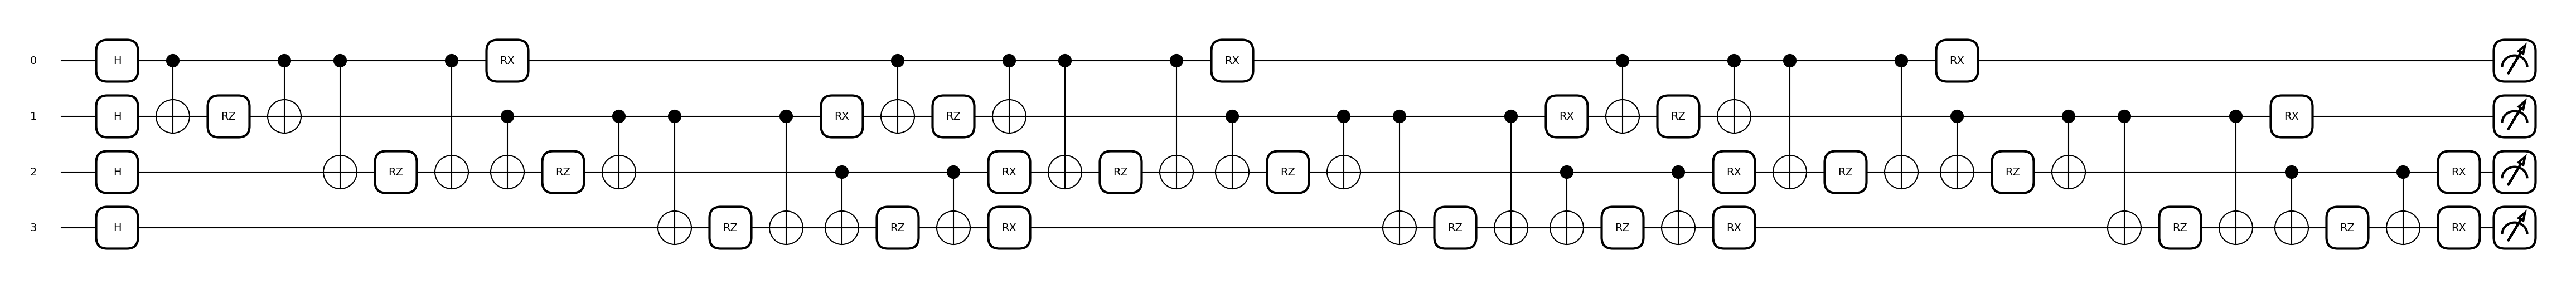

In [8]:
from pennylane import numpy as pnp

# Tres capas QAOA: parámetros [gamma, beta]
p = 3
params = pnp.array([[0.1, 0.1], [0.1, 0.1], [0.1, 0.1]], requires_grad=True)

# Circuito QAOA
@qml.qnode(dev, interface="autograd")
def circuito_qaoa(params):
    # Preparación de la superposición uniforme
    for i in range(n_nodes):
        qml.Hadamard(wires=i)

    # Aplicación de las tres capas
    for k in range(p):
        cost_layer(params[k, 0])
        mixer_layer(params[k, 1])

    return qml.probs(wires=range(n_nodes))

# Visualización del circuito
fig, ax = qml.draw_mpl(circuito_qaoa)(params)
plt.show()


<h3 align="center"><u>Función objetivo y entrenamiento</u></h3>

Buscamos los parámetros que **minimicen la energía esperada**:

$$
\boxed{
\boldsymbol{\theta}^{*}
=
\underset{\boldsymbol{\theta}}{\arg\min}
\mathcal L(\boldsymbol{\theta}),
\qquad
\mathcal L(\boldsymbol{\theta})
=
\langle\psi(\boldsymbol{\theta})|H_C|\psi(\boldsymbol{\theta})\rangle
}
$$

**Minimizamos únicamente $H_C$, no $H_M$**, pero actualizamos los parámetros $\gamma$ y $\beta$ de ambos operadores.

Como $E(\mathbf{x})=-C(\mathbf{x})$:

$$
\boxed{
\mathcal L(\boldsymbol{\theta})
=
\sum_{\mathbf{x}\in\{0,1\}^4}
P_{\boldsymbol{\theta}}(\mathbf{x})E(\mathbf{x})
}
$$

donde $P_{\boldsymbol{\theta}}(\mathbf{x})$ es la **probabilidad de medir** la configuración $\mathbf{x}$.

PennyLane calcula los gradientes mediante **Autograd**, mientras que **Adam** actualiza los parámetros para reducir la energía esperada.


In [9]:
# Configuraciones binarias y energías de MaxCut: E(x) = -C(x)
estados = [format(k, f"0{n_nodes}b") for k in range(2**n_nodes)]
configuraciones = [tuple(map(int, s)) for s in estados]
cortes = np.array([sum(x[i] != x[j] for i, j in edges) for x in configuraciones])
energias = pnp.array(-cortes, requires_grad=False)

# Función objetivo diferenciable
def funcion_objetivo(params):
    return pnp.dot(circuito_qaoa(params), energias)

# Optimización variacional con Adam
opt = qml.AdamOptimizer(stepsize=0.05)
n_iteraciones = 200
historial = [float(funcion_objetivo(params))]

for it in range(n_iteraciones):
    params = opt.step(funcion_objetivo, params)
    energia = float(funcion_objetivo(params))
    historial.append(energia)
    if (it + 1) % 10 == 0:
        print(f"Iteración {it+1:3d} | Energía: {energia:.6f}")

# Resultados del entrenamiento
params_optimos = np.array(params)
probabilidades = np.array(circuito_qaoa(params))
print(f"\nParámetros [gamma, beta]:\n{params_optimos}\n"
      f"Energía: {historial[-1]:.6f} | Cortes esperados: {-historial[-1]:.6f}")

Iteración  10 | Energía: -2.459931
Iteración  20 | Energía: -3.058838
Iteración  30 | Energía: -3.309180
Iteración  40 | Energía: -3.463467
Iteración  50 | Energía: -3.513274
Iteración  60 | Energía: -3.678175
Iteración  70 | Energía: -3.915593
Iteración  80 | Energía: -3.967307
Iteración  90 | Energía: -3.982757
Iteración 100 | Energía: -3.981871
Iteración 110 | Energía: -3.985796
Iteración 120 | Energía: -3.986541
Iteración 130 | Energía: -3.986761
Iteración 140 | Energía: -3.986899
Iteración 150 | Energía: -3.986939
Iteración 160 | Energía: -3.986944
Iteración 170 | Energía: -3.986953
Iteración 180 | Energía: -3.986954
Iteración 190 | Energía: -3.986954
Iteración 200 | Energía: -3.986955

Parámetros [gamma, beta]:
[[-0.66017764  0.33115332]
 [-1.44384789  0.42837377]
 [-1.1959073   0.42497126]]
Energía: -3.986955 | Cortes esperados: 3.986955



<h3 align="center"><u>Análisis y visualización de resultados</u></h3>

Evaluaremos la **convergencia de la energía** y la **distribución de probabilidades** de las 16 configuraciones. Además, calcularemos la **probabilidad de éxito**, definida como la probabilidad de medir cualquiera de las configuraciones que alcanzan el máximo de $C_{\max}=4$ cortes:

$$
\boxed{
P_{\mathrm{éxito}}=
\sum_{\mathbf{x}:C(\mathbf{x})=C_{\max}}
P_{\boldsymbol{\theta}^{*}}(\mathbf{x})
}
$$


Configuración: 0110 (4 cortes) | Máximo: 4 | Probabilidad de éxito: 98.93%


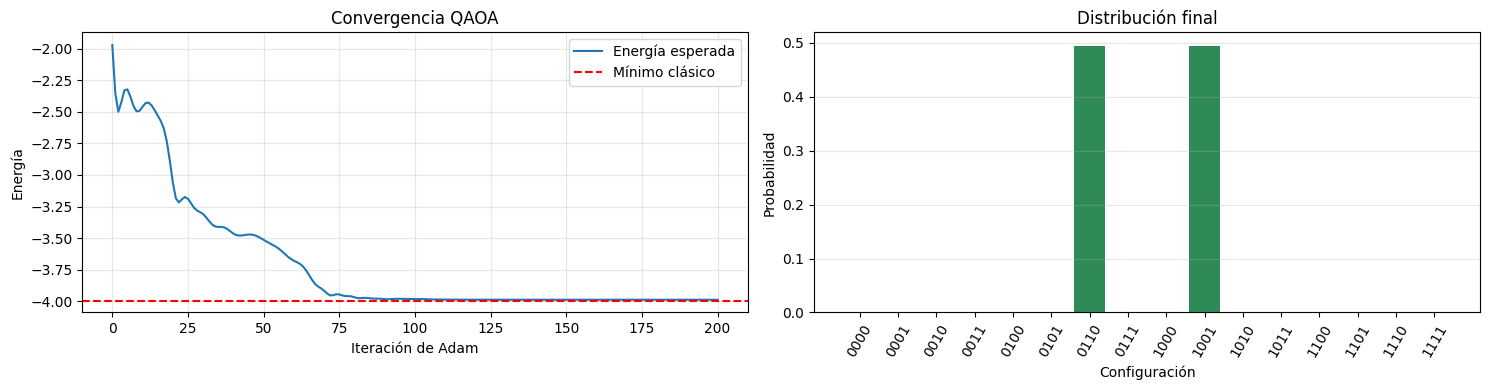

In [10]:
# Configuración más probable y probabilidad de éxito
valor_optimo = int(cortes.max())
indice = int(np.argmax(probabilidades))
prob_exito = float(probabilidades[cortes == valor_optimo].sum())

print(f"Configuración: {estados[indice]} ({cortes[indice]} cortes) | "
      f"Máximo: {valor_optimo} | Probabilidad de éxito: {prob_exito:.2%}")

# Gráficas: convergencia (izquierda) y probabilidades (derecha)
fig, ax = plt.subplots(1, 2, figsize=(15, 4))

ax[0].plot(range(len(historial)), historial, label="Energía esperada")
ax[0].axhline(-valor_optimo, color="red", ls="--", label="Mínimo clásico")
ax[0].set(title="Convergencia QAOA", xlabel="Iteración de Adam", ylabel="Energía")
ax[0].legend(); ax[0].grid(alpha=0.3)

colores = ["seagreen" if c == valor_optimo else "steelblue" for c in cortes]
ax[1].bar(estados, probabilidades, color=colores)
ax[1].set(title="Distribución final", xlabel="Configuración", ylabel="Probabilidad")
ax[1].tick_params(axis="x", rotation=60); ax[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


Con los resultados obtenidos, el circuito **QAOA de tres capas ($p=3$)** identificó la configuración $\mathbf{x}=(0,1,1,0)$, que alcanza el máximo de **4 cortes**. La **probabilidad de éxito fue del 98.93 %**, indicando que una medición del circuito optimizado tiene una probabilidad muy alta de producir una solución óptima.

Este resultado corresponde a una simulación con probabilidades exactas; no implica que QAOA garantice encontrar el óptimo en otros problemas.



# **Conclusión**

La **búsqueda exhaustiva clásica** evalúa las $2^n$ configuraciones posibles para garantizar el óptimo, mientras que **QAOA** utiliza superposición e interferencia cuántica para favorecer soluciones de alta calidad sin enumerarlas explícitamente.

Esto representa una **posible ventaja frente a la búsqueda exhaustiva**, especialmente al aumentar el tamaño del problema; sin embargo, QAOA requiere optimización clásica y mediciones repetidas, por lo que demostrar una **ventaja cuántica computacional** exige compararlo también con algoritmos clásicos eficientes, no únicamente con la búsqueda exhaustiva.


---

Desarrollado por Sebastián González Juárez
Facultad de Ciencias, Universidad Nacional Autónoma de México (UNAM)


© 2026 Sebastián González Juárez. Este notebook fue desarrollado con fines educativos y de investigación. Si el material es reutilizado o adaptado, se agradece conservar la atribución al autor.

  <li><b>Repositorio personal del autor Sebastián González Juárez:</b><br>
<a href="https://github.com/Bayan0708" target="_blank">
https://github.com/Bayan0708
</a>